# Predicting bankruptcy with variable selection and a decision tree
*Augmented Decision, final project. Approach 3 of the brief: combined variable selection and decision-tree classification.*

**Question.** Can a few financial ratios and a readable decision tree help an analyst decide which firms to review for bankruptcy risk?

**Answer in short.** Yes, as a screening tool. L1 variable selection keeps 6 of 92 ratios; a tree of depth 4 built on them flags firms whose estimated bankruptcy risk is at least $1/11$. On 1,364 unseen test firms it catches **31 of 44 bankruptcies** and **halves the decision cost** compared with reviewing no one (0.149 vs 0.323 per firm). A tree on all 92 ratios performs about as well, so selection mainly makes the model simpler, not more accurate.

| Part | Content | Brief, p. 1–2 |
|---|---|---|
| 1 | Problem: target, decision, metric, data, preprocessing | *Formulate the problem clearly* |
| 2 | Methods: split, variable selection, decision tree | *Methods and choices* |
| 3 | Model selection by cross-validation, comparison with baselines | *Evaluation* |
| 4 | Final model and test performance | *Evaluation* |
| 5 | Recommendation and limitations | *Evidence and recommendation* |

Course references are given as *(Lecture, slide)*.

## Setup
Libraries and all fixed settings in one place. Run the notebook from the project folder (it reads `data/data.csv`).

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42                              # one fixed seed for the split, the folds and the models
C_FP, C_FN = 1, 10                     # cost of a needless review, cost of a missed bankruptcy
THRESHOLD = C_FP / (C_FP + C_FN)       # flag when P(bankrupt) >= 1/11 (derived in 1.2)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
GREY, ORANGE = "#9aa5b1", "#c2571a"

# Part 1. Problem formulation

## 1.1 Prediction target
Each row is a firm listed in Taiwan (Taiwan Economic Journal, 1999–2009). The target is `Bankrupt?`: **1 = the firm went bankrupt, 0 = it did not**. The 95 other columns are financial ratios (profitability, debt, liquidity, growth, ...).

In [4]:
data = pd.read_csv("data/data.csv")
data.columns = data.columns.str.strip()            # the raw names start with a space
X, y = data.drop(columns="Bankrupt?"), data["Bankrupt?"]
print(f"{len(data):,} firms, {X.shape[1]} financial ratios, {y.sum()} bankruptcies ({y.mean():.1%})")

6,819 firms, 95 financial ratios, 220 bankruptcies (3.2%)


## 1.2 The decision to support
A credit analyst monitors these firms and decides, for each one, whether to **flag it for an in-depth review** ($a = 1$) or not ($a = 0$). A review costs analyst time; a missed bankruptcy costs the money lent or invested. In units of one review (Lecture 1, slide 8):

| Action \ Outcome | Firm survives ($Y = 0$) | Firm goes bankrupt ($Y = 1$) |
|---|---|---|
| No flag | 0 | $C_{FN} = 10$ (missed bankruptcy) |
| Flag | $C_{FP} = 1$ (needless review) | 0 |

**Assumption.** The data contain no costs. The ratio 10 : 1 is our modelling choice.

**Bayes decision rule** (Lecture 1, slides 19–20). If the firm's bankruptcy probability is $p$, the expected losses are $10\,p$ without a flag and $1\cdot(1-p)$ with a flag. Flagging is better when
$$
1\cdot(1-p) \le 10\,p \quad\Longleftrightarrow\quad p \ge \frac{C_{FP}}{C_{FP}+C_{FN}} = \frac{1}{11} \approx 0.091 .
$$
So the analyst should review a firm **as soon as its bankruptcy risk reaches 9.1%**, far below 50%, because a missed bankruptcy is so expensive. The model's job is to estimate $p$; the threshold follows from the costs and is not tuned.

## 1.3 Evaluation metric
We judge a decision rule by its **average cost per firm** (the empirical risk of Lecture 1, slide 26):
$$
\text{cost per firm} = \frac{C_{FP}\cdot FP + C_{FN}\cdot FN}{n},
$$
where FP is the number of needless reviews, FN the number of missed bankruptcies and $n$ the number of firms. **Lower is better.** We also report recall (share of bankruptcies caught) and the number of flags, which are easier to communicate.

The function below computes these numbers. The table shows why **accuracy is useless here**: never flagging anyone is 96.8% accurate but catches no bankruptcy (Trees lecture, slide 2).

In [5]:
def score(y_true, p_bankrupt):
    # Flag the firms with p >= THRESHOLD, then count the outcomes and the cost per firm
    y_true, flag = np.asarray(y_true), np.asarray(p_bankrupt) >= THRESHOLD
    tp, fp = int((flag & (y_true == 1)).sum()), int((flag & (y_true == 0)).sum())
    fn = int((~flag & (y_true == 1)).sum())
    return {"cost per firm": (C_FP * fp + C_FN * fn) / len(y_true),
            "accuracy": float((flag == y_true).mean()), "recall": tp / (tp + fn),
            "caught": tp, "missed": fn, "false alarms": fp}

pd.DataFrame([score(y, np.zeros(len(y))), score(y, np.ones(len(y)))],
             index=["never flag", "flag every firm"]).round(3)

,cost per firm,accuracy,recall,caught,missed,false alarms
never flag,0.323,0.968,0.0,0,220,0
flag every firm,0.968,0.032,1.0,220,0,6599


Never flagging costs **0.323 per firm** ($10 \times 3.2\%$). This is the baseline any model must beat.

## 1.4 Dataset description
- **Source:** *Taiwanese Bankruptcy Prediction*, UCI Machine Learning Repository (2020), https://doi.org/10.24432/C5004D, licence CC BY 4.0. Original study: Liang, Lu, Tsai and Shih (2016), *European Journal of Operational Research* 252(2), 561–572.
- **Observations and variables:** 6,819 firms, 95 numeric ratios, 1 binary target.
- **Target distribution:** strongly imbalanced, see the plot.

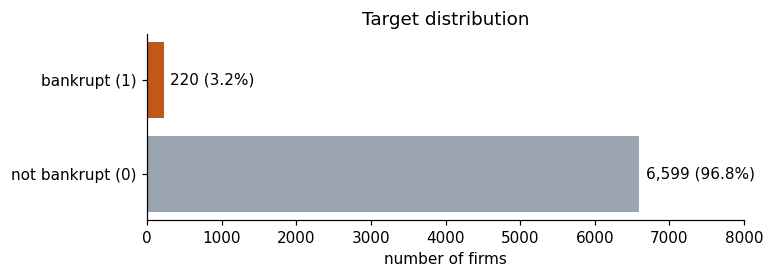

In [6]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2.2))
bars = ax.barh(["not bankrupt (0)", "bankrupt (1)"], counts.values, color=[GREY, ORANGE])
ax.bar_label(bars, labels=[f"{n:,} ({n / len(y):.1%})" for n in counts.values], padding=4)
ax.set(xlabel="number of firms", xlim=(0, 8000), title="Target distribution")
plt.show()

With only 220 bankruptcies, every estimate will be noisy. We therefore stratify every split (each part keeps 3.2% bankruptcies) and use cross-validation rather than a single validation set.

**Data quality.** The next cell checks missing values, duplicates, constant and identical columns, and very large values.

In [7]:
constant = [c for c in X if X[c].nunique() == 1]
identical = [(a, b) for i, a in enumerate(X) for b in list(X)[i + 1:] if X[a].equals(X[b])]
print("Missing values:", int(X.isna().sum().sum()), "| duplicate rows:", int(data.duplicated().sum()))
print("Constant columns:", constant)
print("Identical column pairs:", identical)
print(f"Ratios with values above 1: {(X.max() > 1).sum()} (largest value {X.max().max():.0e})")

Missing values: 0 | duplicate rows: 0
Constant columns: ['Net Income Flag']
Identical column pairs: [('Current Liabilities/Liability', 'Current Liability to Liability'), ('Current Liabilities/Equity', 'Current Liability to Equity')]
Ratios with values above 1: 24 (largest value 1e+10)


- **No missing values and no duplicate rows:** nothing to impute or remove.
- **`Net Income Flag` is constant** and **two pairs of columns are exact copies**: they carry no extra information and are dropped (inside every training split, see 2.2).
- **24 ratios contain very large values** (up to $10^{10}$) while most lie in $[0, 1]$. We do not change the recorded values. A decision tree only uses the order of values, so it is not affected; for the L1 selector we standardise the columns.

## 1.5 Exploring the data
We look at the **development firms only** (same split as in 2.1): the test firms stay locked (Lecture 2, slide 3).

In [8]:
dev_rows, _ = train_test_split(np.arange(len(data)), test_size=0.2, stratify=y, random_state=SEED)
X_eda, y_eda = X.iloc[dev_rows].drop(columns="Net Income Flag"), y.iloc[dev_rows]
print(f"{len(X_eda):,} development firms, {X_eda.shape[1]} ratios, {y_eda.sum()} bankruptcies ({y_eda.mean():.1%})")

5,455 development firms, 94 ratios, 176 bankruptcies (3.2%)


**Scales:** the five ratios with the largest maximum.

In [18]:
ranges = pd.DataFrame({"minimum": X_eda.min(), "median": X_eda.median(), "maximum": X_eda.max()})
ranges.sort_values("maximum", ascending=False).head(5).round(3)

,minimum,median,maximum
Cash Turnover Rate,0.0,1.140000e+09,1.000000e+10
Quick Asset Turnover Rate,0.0,0.000000e+00,1.000000e+10
Current Asset Turnover Rate,0.0,0.000000e+00,1.000000e+10
Inventory Turnover Rate (times),0.0,1.000000e-03,9.990000e+09
Fixed Assets Turnover Frequency,0.0,1.000000e-03,9.990000e+09


- Most ratios lie between 0 and 1, but these five reach about $10^{10}$.

**Link with bankruptcy:** correlation of each ratio with `Bankrupt?` (negative = more bankruptcies when the ratio is low).

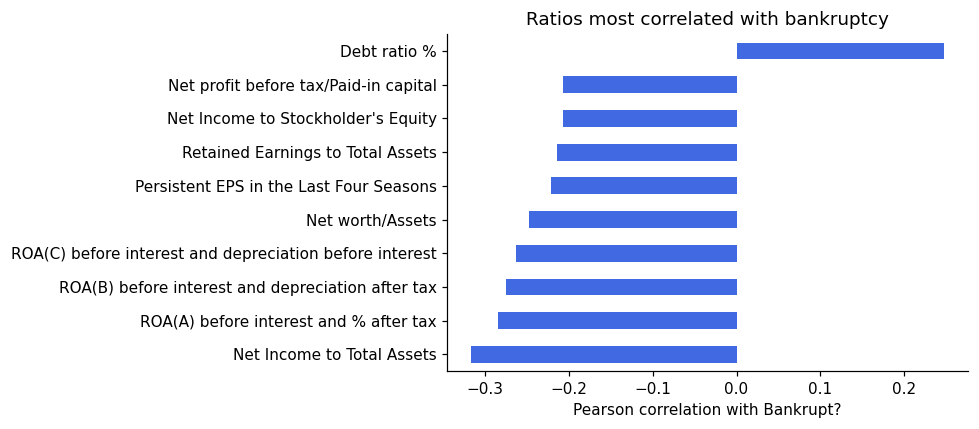

In [28]:
correlation = X_eda.corrwith(y_eda)
top10 = correlation.abs().sort_values(ascending=False).head(10).index

correlation[top10].sort_values().plot.barh(color='royalblue', figsize=(9, 4))
plt.xlabel("Pearson correlation with Bankrupt?")
plt.title("Ratios most correlated with bankruptcy")
plt.tight_layout()
plt.show()

- The correlations are weak (the largest is about $-0.32$): no single ratio separates the two groups.
- Profitable firms go bankrupt less often; indebted firms more often.

**Average value** of three ratios for survivors (0) and bankrupt firms (1):

In [11]:
names = ["Net Income to Total Assets", "Debt ratio %", "Persistent EPS in the Last Four Seasons"]
X_eda.groupby(y_eda)[names].mean().T.round(3)

Bankrupt?,0,1
Net Income to Total Assets,0.810,0.738
Debt ratio %,0.111,0.187
Persistent EPS in the Last Four Seasons,0.230,0.190


- Bankrupt firms are on average less profitable and more indebted.

**Redundancy:** correlation between four ratios.

In [29]:
four = ["Net Income to Total Assets", "ROA(A) before interest and % after tax", "Debt ratio %", "Net worth/Assets"]
X_eda[four].corr().round(2)

,Net Income to Total Assets,ROA(A) before interest and % after tax,Debt ratio %,Net worth/Assets
Net Income to Total Assets,1.00,0.96,-0.28,0.28
ROA(A) before interest and % after tax,0.96,1.00,-0.26,0.26
Debt ratio %,-0.28,-0.26,1.00,-1.00
Net worth/Assets,0.28,0.26,-1.00,1.00


- The two profitability ratios are near-copies (0.96).
- `Debt ratio %` and `Net worth/Assets` are exact opposites ($-1$): they add up to 1.
- So the 92 ratios contain less independent information than their number suggests (Lecture 3, slide 18).

## 1.6 Required preprocessing

| Issue | Action | Learned from |
|---|---|---|
| Column names start with a space | strip them | — |
| Constant and identical columns | drop them | training rows of each split |
| Ratios on very different scales | standardise, **for the L1 selector only**; the tree gets the original values | training rows of each split |
| 3.2% bankruptcies | stratified split and folds; cost-based threshold; no resampling | — |

Everything that is *learned* from the data is learned from training rows only, inside every split, as the brief requires.

# Part 2. Methods

## 2.1 Training, validation and test (Lecture 2, slides 2–3)

| Part | Role | Size |
|---|---|---|
| **Development data** (80%) | choose the model by 5-fold cross-validation | 5,455 firms, 176 bankrupt |
| **Test data** (20%) | evaluate the final, frozen model **once** | 1,364 firms, 44 bankrupt |

**5-fold cross-validation:** the development data are cut into 5 parts. Five times, the model learns on 4 parts and is scored on the 5th. Every development firm is used for validation exactly once. The split and folds are the same as in `variable_selection.ipynb` (same seed, same procedure).

In [13]:
row_ids = np.arange(len(data))
dev, test = train_test_split(row_ids, test_size=0.2, stratify=y, random_state=SEED)
dev, test = np.sort(dev), np.sort(test)
X_dev, y_dev, X_test, y_test = X.iloc[dev], y.iloc[dev], X.iloc[test], y.iloc[test]

fold = np.zeros(len(dev), dtype=int)                       # validation fold (1-5) of each development firm
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, valid) in enumerate(folds.split(X_dev, y_dev), start=1):
    fold[valid] = k

pd.DataFrame({"firms": [len(dev), len(test)], "bankrupt": [y_dev.sum(), y_test.sum()]},
             index=["development", "test (locked)"])

,firms,bankrupt
development,5455,176
test (locked),1364,44


## 2.2 Variable selection with an L1 penalty (Lectures 3–4)
**Why select variables?** 92 usable ratios, many of them near-copies, make a tree harder to read and less stable. A short list is easier to explain and to monitor (Lecture 3, slide 18).

**How.** Lecture 4 (slide 7) adds an L1 penalty $\lambda\|b\|_1$ to the fitting loss; it sets some coefficients **exactly to zero**. Our target is binary, so we use the logistic loss instead of squared error (Lecture 2, appendix F):
$$
\min_{b_0,\,b}\; \frac1n\sum_{i=1}^n \Big[-y_i\log q_i-(1-y_i)\log(1-q_i)\Big] + \lambda\sum_j |b_j|,
\qquad q_i=\frac{1}{1+e^{-(b_0+z_i^\top b)}} .
$$
$z_i$ are the standardised ratios of firm $i$, $q_i$ its estimated bankruptcy probability, $b$ the coefficients and $b_0$ the (unpenalised) intercept. **We keep the ratios with $b_j \ne 0$.** The logistic model is only used to choose inputs; the classifier is the tree.

In scikit-learn the penalty strength is set through $C$: **smaller $C$ = stronger penalty = fewer ratios.** The function below does the whole selection on the rows it receives, so it can be refitted inside every training split. Its settings are those of `variable_selection.ipynb`.

In [14]:
def select_variables(X_train, y_train, C):
    keep = []
    for name in X_train.columns:                          # drop constant columns and exact copies
        column = X_train[name]
        if column.nunique() > 1 and not any(column.equals(X_train[k]) for k in keep):
            keep.append(name)
    if C is None:                                         # "no selection": cleanup only
        return keep
    Z = StandardScaler().fit_transform(X_train[keep])     # standardise: a fair penalty for every ratio
    lasso = LogisticRegression(l1_ratio=1, C=C, solver="saga", tol=1e-4,
                               max_iter=20_000, random_state=SEED).fit(Z, y_train)
    return [name for name, b in zip(keep, lasso.coef_[0]) if abs(b) >= 1e-6]

**Regularisation path** (Lecture 4, slide 19). How many ratios does the selector keep for different $C$? This only describes the selector on the development data; it does not choose $C$.

In [15]:
C_path = [0.003, 0.01, 0.03, 0.1, 0.3, 1]
n_kept = [len(select_variables(X_dev, y_dev, C)) for C in C_path]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(C_path, n_kept, "o-", color=ORANGE)
for C, n in zip(C_path, n_kept):
    ax.annotate(str(n), (C, n), textcoords="offset points", xytext=(0, 7), ha="center")
ax.axhline(92, color=GREY, ls="--", lw=1)
ax.text(C_path[0], 87, "all 92 ratios", color=GREY, fontsize=8)
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)", ylabel="ratios kept",
       title="L1 regularisation path on the development data")
plt.show()

KeyboardInterrupt: 

At $C = 0.003$ the penalty is so strong that no ratio is left. $C = 0.01$ keeps a handful of ratios, $C = 0.1$ about a third, and from $C = 1$ on almost all of them are kept, so selection loses its point. We therefore compare three options in Part 3: **$C = 0.01$, $C = 0.1$ and no selection** (all 92 ratios).

## 2.3 Decision tree (Trees lecture, slides 5–9)
A tree asks a firm a sequence of yes/no questions such as *"Is the debt ratio above 0.4?"*. Each question is the split that most reduces the **Gini impurity** $G(q) = 2q(1-q)$ of the groups, where $q$ is the share of bankrupt firms (slide 7). The firm ends in a **leaf**; the share of bankrupt training firms in that leaf is its estimated probability $p$, which we compare with $1/11$.

**Why a tree?** The analyst can read and challenge its rules; it captures thresholds and interactions (slide 8); it only uses the order of values, so the large values of 1.4 do not matter; each leaf gives the probability the decision rule needs.

**Hyperparameters.**

| Setting | Meaning | Values tried | Why |
|---|---|---|---|
| `max_depth` | maximum number of questions in a row | 2, 3, 4, 5 | readable trees; deeper trees risk overfitting |
| `min_samples_leaf` | minimum number of training firms in a leaf | 10, 25, 50, 100 | with 10 firms, one bankruptcy already gives $p = 0.1 \ge 1/11$: unstable probabilities |
| `criterion` | split quality | Gini | the impurity of the course |
| `class_weight` | reweighting of classes | none | the cost asymmetry is already in the threshold; reweighting would count it twice |

**The trade-off** (Lecture 2, slides 4 and 8). A tree that is too small cannot represent the pattern (**underfitting**); a tree that is too large memorises chance details of the training firms (**overfitting**). Training error always falls as the tree grows, so we choose the size on validation data (Trees lecture, slide 9).

# Part 3. Model selection by cross-validation
We compare $3 \times 4 \times 4 = 48$ candidates (selection option × depth × leaf size). For each of the 5 folds, the next cell
1. **selects the ratios on the 4 training folds only**, so the validation firms cannot influence the selection (no data leakage);
2. trains every tree on those training firms, using only the selected ratios in their original values;
3. scores it on the 5th fold with the cost per firm.

It takes about a minute.

In [ ]:
OPTIONS = {"C = 0.01": 0.01, "C = 0.1": 0.1, "no selection": None}
DEPTHS, LEAVES = [2, 3, 4, 5], [10, 25, 50, 100]

rows = []
for k in range(1, 6):
    train, valid = fold != k, fold == k
    for option, C in OPTIONS.items():
        columns = select_variables(X_dev[train], y_dev[train], C)        # training folds only
        for depth in DEPTHS:
            for leaf in LEAVES:
                tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=SEED)
                tree.fit(X_dev[train][columns], y_dev[train])
                p = tree.predict_proba(X_dev[valid][columns])[:, 1]
                rows.append({"fold": k, "selection": option, "depth": depth, "leaf": leaf,
                             "ratios": len(columns), **score(y_dev[valid], p)})

cv = pd.DataFrame(rows)
summary = (cv.groupby(["selection", "depth", "leaf"])
           .agg(mean_cost=("cost per firm", "mean"), std_cost=("cost per firm", "std"),
                recall=("recall", "mean"), ratios=("ratios", "mean"))
           .reset_index())
print(f"{len(cv)} trees trained and scored ({len(summary)} candidates x 5 folds)")

240 trees trained and scored (48 candidates x 5 folds)


Each cell below is the **mean validation cost per firm** of one candidate. Darker = cheaper. Never flagging costs about 0.32.

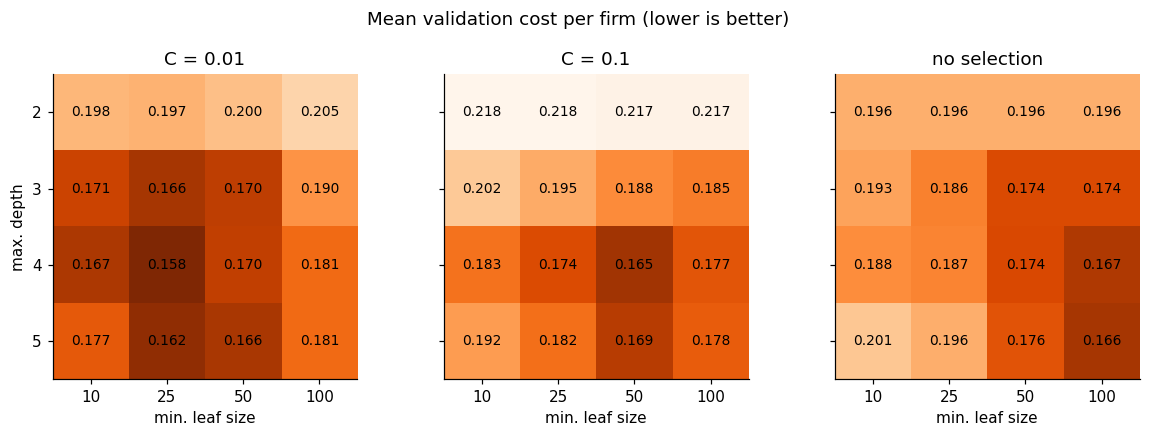

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, option in zip(axes, OPTIONS):
    grid = summary[summary["selection"] == option].pivot(index="depth", columns="leaf", values="mean_cost")
    ax.imshow(grid, cmap="Oranges_r", vmin=summary["mean_cost"].min(), vmax=summary["mean_cost"].max())
    for i, depth in enumerate(grid.index):
        for j, leaf in enumerate(grid.columns):
            ax.text(j, i, f"{grid.loc[depth, leaf]:.3f}", ha="center", va="center", fontsize=9)
    ax.set(title=option, xlabel="min. leaf size", xticks=range(4), xticklabels=grid.columns,
           yticks=range(4), yticklabels=grid.index)
axes[0].set_ylabel("max. depth")
fig.suptitle("Mean validation cost per firm (lower is better)", y=1.04)
plt.show()

**Reading the heatmap.**
- **Depth 2 is too simple** in every panel (about 0.20): underfitting.
- **Leaves of 10 firms** are usually worse than larger ones: their probabilities are unstable.
- Beyond depth 4, extra questions no longer help. The cheapest region is **depth 3–5 with leaves of 25–50** and the strongest selection, $C = 0.01$.

**Selection rule, fixed in advance:** choose the candidate with the lowest mean validation cost. The test set plays no part in it. The table compares the winner with the best tree without selection and with the never-flag baseline.

In [ ]:
best = summary.sort_values("mean_cost").iloc[0]
best_all = summary[summary["selection"] == "no selection"].sort_values("mean_cost").iloc[0]
never_flag = np.mean([score(y_dev[fold == k], np.zeros((fold == k).sum()))["cost per firm"] for k in range(1, 6)])

comparison = pd.DataFrame([best, best_all], index=["chosen model", "best without selection"])
comparison.loc["never flag", ["mean_cost", "recall", "ratios"]] = [never_flag, 0, 0]
comparison[["depth", "leaf"]] = comparison[["depth", "leaf"]].astype("Int64")
comparison.round(3)

,selection,depth,leaf,mean_cost,std_cost,recall,ratios
chosen model,C = 0.01,4,25,0.158,0.014,0.693,5.4
best without selection,no selection,5,100,0.166,0.028,0.693,92.0
never flag,NaN,<NA>,<NA>,0.323,NaN,0.000,0.0


**The chosen model: L1 selection with $C = 0.01$, depth 4, at least 25 firms per leaf.**
- It **halves the cost** of never flagging (0.158 vs 0.323) and catches about 70% of the bankruptcies.
- It is slightly cheaper than the best tree on all 92 ratios (0.158 vs 0.166), but the difference is **smaller than the spread between folds** (`std_cost`). We therefore do not claim that selection improves prediction; its advantage is **about 5 ratios instead of 92** at the same cost.
- Choosing among 48 candidates on the same folds makes the winner's validation score slightly optimistic (Lecture 2, slide 16). The untouched test set gives the honest estimate.

# Part 4. Final model and test performance

## 4.1 Refit and read the final tree
The settings are now frozen. We refit the whole procedure on all 5,455 development firms: selection with $C = 0.01$, then the tree. Refitting after validation is allowed because the test set is still untouched (Lecture 2, slide 3).

In the plot, a firm that answers *yes* goes left. `samples` is the share of firms reaching the box, `value` = [share not bankrupt, share bankrupt]. **Orange boxes have a bankrupt share of at least 1/11: their firms are flagged.**

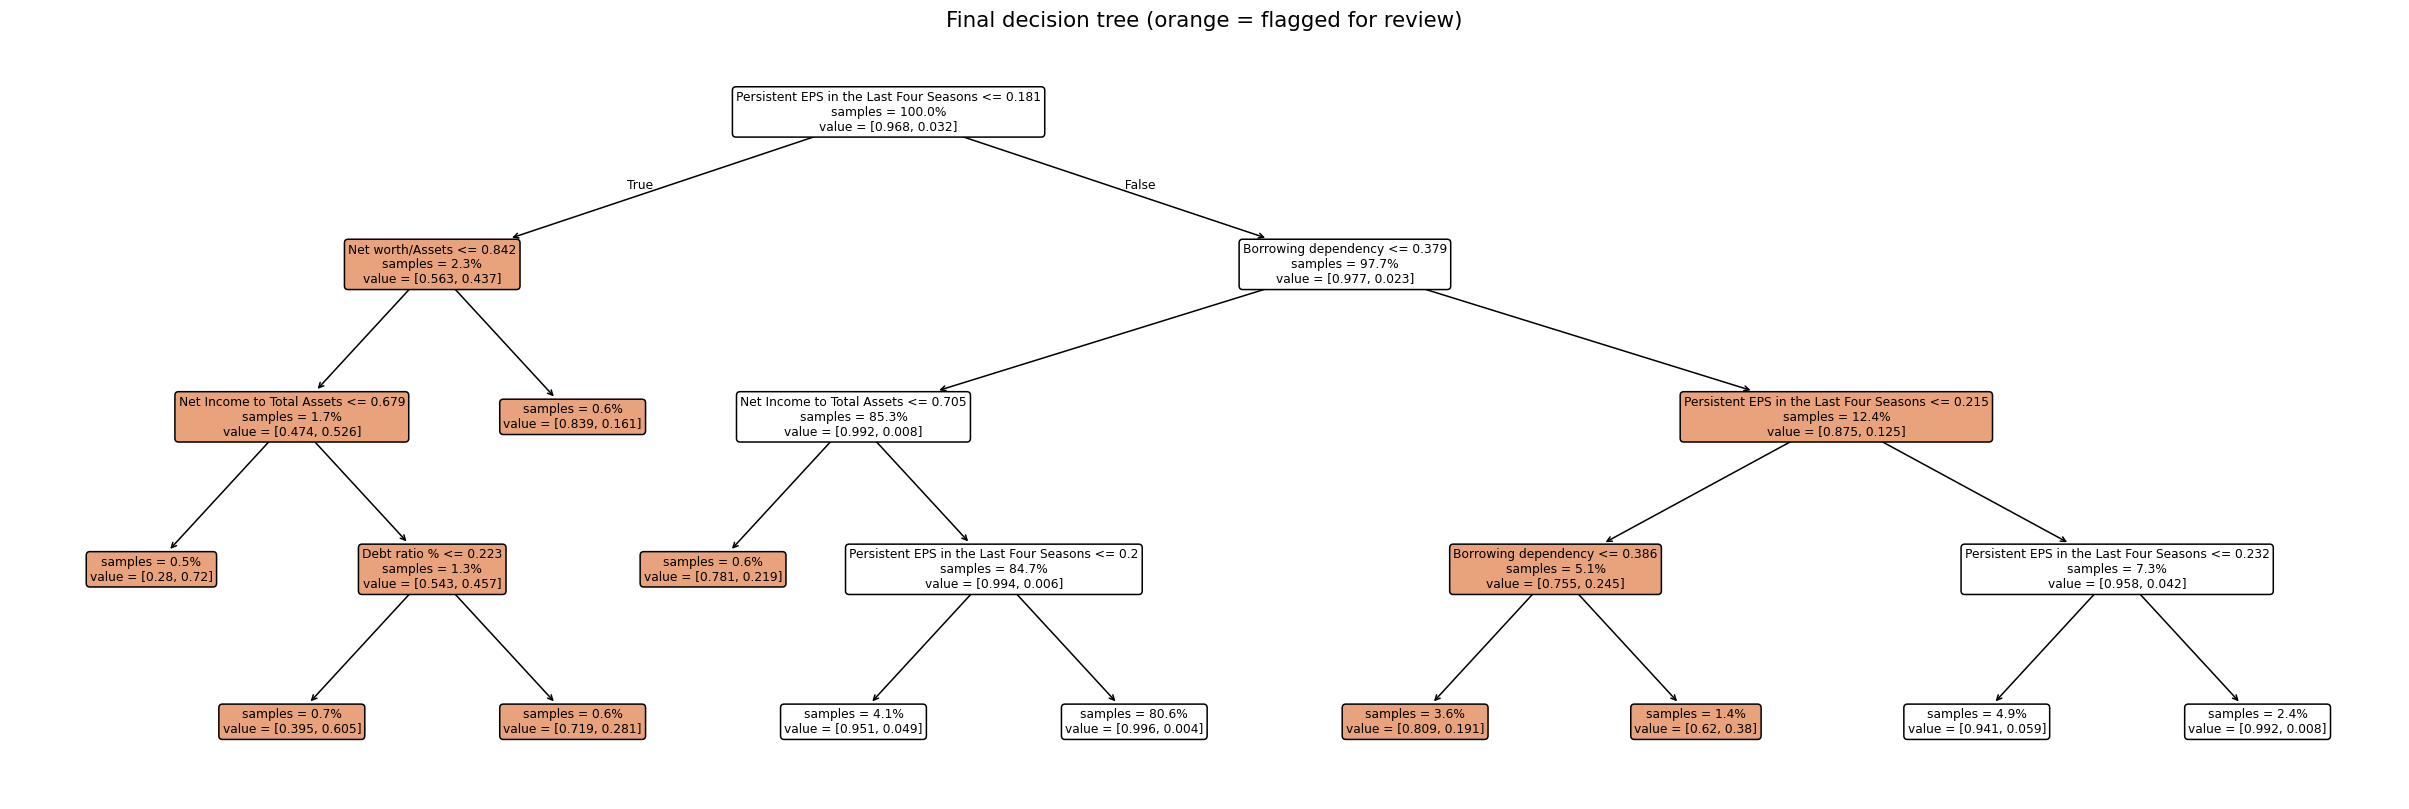

,share of Gini reduction
Persistent EPS in the Last Four Seasons,0.614
Borrowing dependency,0.220
Net worth/Assets,0.067
Net Income to Total Assets,0.058
Debt ratio %,0.039
ROA(B) before interest and depreciation after tax,0.000


In [ ]:
final_columns = select_variables(X_dev, y_dev, OPTIONS[best["selection"]])
final_tree = DecisionTreeClassifier(max_depth=int(best["depth"]), min_samples_leaf=int(best["leaf"]),
                                    random_state=SEED).fit(X_dev[final_columns], y_dev)

fig, ax = plt.subplots(figsize=(28, 9))
boxes = plot_tree(final_tree, feature_names=final_columns, proportion=True, impurity=False,
                  rounded=True, fontsize=8, ax=ax)
boxes = [b for b in boxes if b.get_bbox_patch() is not None]       # node boxes, in node order
for box, share in zip(boxes, final_tree.tree_.value[:, 0, 1]):
    box.get_bbox_patch().set_facecolor("#e8a27c" if share >= THRESHOLD else "white")
ax.set_title("Final decision tree (orange = flagged for review)", fontsize=14)
plt.show()

used = pd.Series(final_tree.feature_importances_, index=final_columns).sort_values(ascending=False)
used.rename("share of Gini reduction").round(3).to_frame()

**How to read it.**
- The selector keeps 6 ratios; the tree uses 5 of them (one has zero importance).
- **First question: low *Persistent EPS*** (earnings per share over the last four quarters). Only 2.3% of firms answer yes, but 44% of them went bankrupt, about 14 times the average rate. Persistently low earnings are the strongest warning sign.
- For the other 97.7%, the tree asks about **Borrowing dependency**: firms that rely heavily on borrowing end in flagged leaves.
- The thresholds are on the scale supplied in the dataset (mostly rescaled to $[0, 1]$), not in currency units.
- *Debt ratio %* and *Net worth/Assets* add up to exactly 1, so they carry the same information. The L1 selector does not remove this redundancy.

## 4.2 The one and only test
We now evaluate the frozen model on the 1,364 test firms it has never seen, together with the two references. Nothing is changed after this point: tuning on the test set would make it part of the model choice (Lecture 2, slide 3).

In [ ]:
reference_columns = select_variables(X_dev, y_dev, None)
reference_tree = DecisionTreeClassifier(max_depth=int(best_all["depth"]), min_samples_leaf=int(best_all["leaf"]),
                                        random_state=SEED).fit(X_dev[reference_columns], y_dev)

test_p = {"chosen model": final_tree.predict_proba(X_test[final_columns])[:, 1],
          "best without selection": reference_tree.predict_proba(X_test[reference_columns])[:, 1],
          "never flag": np.zeros(len(y_test))}
results = pd.DataFrame({name: score(y_test, p) for name, p in test_p.items()}).T
results.insert(0, "validation cost per firm", [best["mean_cost"], best_all["mean_cost"], never_flag])
results.insert(0, "ratios", [len(final_columns), len(reference_columns), 0])
results[["ratios", "caught", "missed", "false alarms"]] = results[["ratios", "caught", "missed", "false alarms"]].astype(int)
results.round(3)

,ratios,validation cost per firm,cost per firm,accuracy,recall,caught,missed,false alarms
chosen model,6,0.158,0.149,0.937,0.705,31,13,73
best without selection,92,0.166,0.174,0.898,0.750,33,11,128
never flag,0,0.323,0.323,0.968,0.000,0,44,0


## 4.3 Results
1. **The chosen model halves the decision cost:** 0.149 per firm on the test set against 0.323 for never flagging. Out of 1,364 firms, the cost falls from 440 units (44 missed bankruptcies × 10) to 203 (13 × 10 for missed bankruptcies + 73 × 1 for needless reviews).
2. **It catches 31 of the 44 bankruptcies (70%)** and flags 104 firms. About one flagged firm in three is truly at risk, against one in thirty without the model.
3. **Selection simplifies without losing performance.** With 6 instead of 92 ratios, the chosen model costs less than the best tree on all ratios on the test set (0.149 vs 0.174): it catches 2 fewer bankruptcies but raises 55 fewer false alarms. On validation the two were within noise of each other.
4. **The test cost (0.149) is close to the validation cost (0.158)**, so the model choice was not overly optimistic.

# Part 5. Recommendation and limitations

**Recommendation.** Use the tree as a **first screening tool**: it tells the analyst which firms to review first, and its five questions can be explained and checked. It supports the review; it does not replace it, and it does not justify automatic credit decisions.

**Limitations.**
- **Small number of bankruptcies.** The test set has 44. One more or one fewer missed bankruptcy changes the test cost by $10/1364 \approx 0.007$, so the comparison between the two trees rests on a few firms.
- **Assumed costs.** The 10 : 1 cost ratio is a modelling choice. Another ratio changes the threshold and could change the chosen model.
- **Selection is not a proof of relevance.** The selected ratios can change between training samples, a zero coefficient does not prove that a ratio is useless, and a selected ratio is not a cause of bankruptcy (Lecture 3, slides 17–19; Lecture 4, slide 16).
- **Data.** Some ratios mix two scales (values up to $10^{10}$); the data have no dates and no company identifiers, so we cannot check performance on later years. The data cover Taiwan in 1999–2009 and may not transfer to other markets or periods.
- **One single tree.** An ensemble of many trees would probably predict better but would lose the readable rules that make this tool usable for an analyst.

**LLM use.** An LLM helped prepare this notebook. As required by the brief, the full prompts and answers are reproduced verbatim in the appendix of the PDF report.